# 랜덤 포레스트 실습

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/slides/v2/ml1/week07/random_forest/lab/random_forest.ipynb)

서로 다른 나무 여럿의 다수결. 숲을 직접 만들고, OOB 와 특징 중요도를 본다.

- **파트 1**: 부트스트랩 + 나무 + 다수결로 숲 직접 만들기 (붓꽃)
- **파트 2**: OOB 점수 직접 계산, 나무 수에 따른 정확도 (당뇨병)
- **파트 3**: 타이타닉: 한 그루 vs 숲, 특징 중요도

`None` 으로 비워 둔 `TODO` 줄을 채우고 셀을 차례로 실행하세요.

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold

In [ ]:
def download(url, name):
    os.makedirs("data", exist_ok=True)
    path = f"data/{name}"
    if not os.path.exists(path):
        import urllib.request; urllib.request.urlretrieve(url, path)
    return path

SEABORN = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/"
iris = pd.read_csv(download(SEABORN + "iris.csv", "iris.csv"))
X = iris[["petal_length", "petal_width"]].to_numpy(); y = iris["species"].to_numpy()

## 파트 1. 숲 직접 만들기

1. 부트스트랩: 150송이에서 복원 추출로 150송이  2. 나무 한 그루 (질문마다 특징 1개만 무작위로: `max_features=1`)  3. 100번 반복  4. 다수결

In [ ]:
def bootstrap_indices(n, rng):
    return None  # TODO: n random indices WITH replacement

def grow_forest(X, y, n_trees, seed=0):
    rng = np.random.default_rng(seed)
    trees, in_bag = [], []
    for k in range(n_trees):
        idx = bootstrap_indices(len(y), rng)
        tree = DecisionTreeClassifier(max_features=1, random_state=k).fit(X[idx], y[idx])
        trees.append(tree); in_bag.append(np.unique(idx))
    return trees, in_bag

def forest_votes(trees, x):
    votes = [t.predict(x.reshape(1, -1))[0] for t in trees]
    labels, counts = np.unique(votes, return_counts=True)
    return {str(l): int(c) for l, c in zip(labels, counts)}

trees, in_bag = grow_forest(X, y, 100)
print("distinct flowers in the first bootstrap sample:", len(in_bag[0]), "/ 150")
for flower in [[5.0, 1.7], [4.9, 1.6], [1.5, 0.2]]:
    print(flower, forest_votes(trees, np.array(flower)))

**예상 결과**

```
distinct flowers in the first bootstrap sample: 95 / 150
[5.0, 1.7] {'versicolor': 71, 'virginica': 29}
[4.9, 1.6] {'versicolor': 93, 'virginica': 7}
[1.5, 0.2] {'setosa': 100}
```

## 파트 2. OOB 점수와 나무 수

당뇨병 768명. 데이터마다, 그 데이터를 **학습에 안 쓴** 나무들만 모아 다수결 → 맞았나?

In [ ]:
cols = ["pregnancies", "glucose", "blood_pressure", "skin_thickness", "insulin", "bmi", "pedigree", "age", "outcome"]
pima = pd.read_csv(download("https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv", "pima.csv"), header=None, names=cols)
Xp, yp = pima[cols[:-1]].to_numpy(float), pima["outcome"].to_numpy()

trees_p, in_bag_p = grow_forest(Xp, yp, 300)
correct, counted = 0, 0
for i in range(len(yp)):
    voters = None  # TODO: trees that did NOT see row i
    if voters:
        votes = [t.predict(Xp[i:i + 1])[0] for t in voters]
        correct += int(np.bincount(votes).argmax() == yp[i]); counted += 1
print(f"my OOB accuracy: {correct / counted:.3f}  (rows scored: {counted})")
print("sklearn oob_score_:", round(RandomForestClassifier(300, oob_score=True, random_state=0).fit(Xp, yp).oob_score_, 3))

**예상 결과**

```
my OOB accuracy: 0.763  (rows scored: 768)
sklearn oob_score_: 0.758
```

In [ ]:
cv = StratifiedKFold(5, shuffle=True, random_state=0)
print("one full tree:", round(cross_val_score(DecisionTreeClassifier(random_state=0), Xp, yp, cv=cv).mean(), 3))
ns = [1, 3, 10, 30, 100, 300]
accs = [cross_val_score(RandomForestClassifier(n, random_state=0), Xp, yp, cv=cv).mean() for n in ns]
plt.semilogx(ns, accs, "o-"); plt.xlabel("number of trees"); plt.ylabel("5-fold CV accuracy"); plt.show()
print([round(float(a), 3) for a in accs])

**예상 결과**

```
one full tree: 0.686
[0.685, 0.728, 0.744, 0.758, 0.744, 0.757]
```

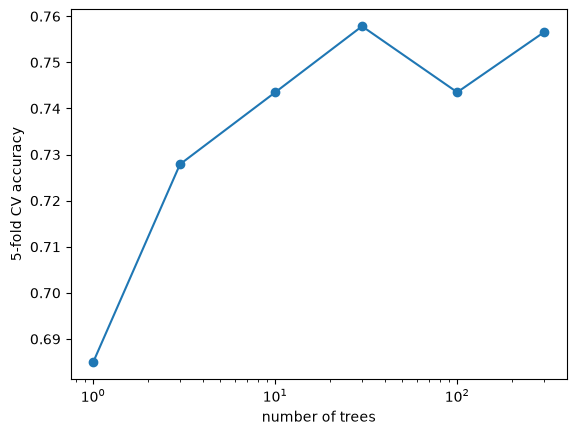

## 파트 3. 타이타닉: 한 그루 vs 숲

In [ ]:
titanic = pd.read_csv(download(SEABORN + "titanic.csv", "titanic.csv"))
df = titanic[["survived", "pclass", "sex", "age", "sibsp", "parch", "fare"]].copy()
df["sex"] = (df["sex"] == "female").astype(int)
df["age"] = df["age"].fillna(df["age"].median())
Xt, yt = df.drop(columns="survived").to_numpy(), df["survived"].to_numpy()
names = list(df.columns[1:])
tree_acc = cross_val_score(DecisionTreeClassifier(random_state=0), Xt, yt, cv=cv).mean()
forest = RandomForestClassifier(300, random_state=0)
forest_acc = None  # TODO: 5-fold CV accuracy of the forest
print(f"one tree {tree_acc:.3f}   forest {forest_acc:.3f}")
imp = forest.fit(Xt, yt).feature_importances_
for n, v in sorted(zip(names, imp), key=lambda t: -t[1]):
    print(f"{n:6s} {v:.3f}")

**예상 결과**

```
one tree 0.788   forest 0.804
fare   0.292
sex    0.274
age    0.263
pclass 0.087
sibsp  0.049
parch  0.036
```

**확인 질문**
1. 파트 1 에서 `max_features=1` 을 지우면 (모든 특징을 후보로) 표가 어떻게 달라지나? 나무들이 더 닮을까?
2. 파트 2 의 직접 계산한 OOB 와 scikit-learn 의 값이 조금 다른 이유는? (힌트: 나무를 만드는 방법)
3. 파트 3 에서 가장 중요한 특징은? 결정 트리 실습의 첫 질문과 같은가?
4. (도전) 파트 3 에서 `fare` 대신 아무 뜻 없는 난수 열을 넣으면 그 열의 중요도는 0 일까? 왜 아닐까?

데이터 출처: Fisher (1936) Iris · Titanic (seaborn-data) · Pima Indians Diabetes (NIDDK, UCI).